In [4]:
from __future__ import annotations

import sys
from pathlib import Path

import cv2
import numpy as np
import pdfplumber
import torch
from PIL import Image
from transformers import pipeline

ROOT = Path.cwd().resolve()
while not (ROOT / "norm-docs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from normatives_pipeline.config import ocr_config, parser_config
from normatives_pipeline.parser.extractors import (
    extract_formulas,
    extract_unnumbered_formulas,
)
from normatives_pipeline.parser.models import Formula, ParsedDocument


In [5]:
pdf_path = ROOT / "norm-docs" / "СП 22.13330.2016.pdf"
pdf = pdfplumber.open(pdf_path)
pages = pdf.pages

print(f"страниц: {len(pages)}")


страниц: 222


In [6]:
DPI = 300
out_dir = ROOT / "normatives_pipeline" / "research" / "pages"
out_dir.mkdir(parents=True, exist_ok=True)

page_image_paths = []
for i, page in enumerate(pages, start=1):
    img = page.to_image(resolution=DPI).original
    path = out_dir / f"page_{i:03d}.png"
    img.save(path)
    page_image_paths.append(path)

print(f"изображений сохранено: {len(page_image_paths)}")


изображений сохранено: 222



0: 1024x736 1 title, 13 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 116.7ms
Speed: 14.7ms preprocess, 116.7ms inference, 733.4ms postprocess per image at shape (1, 3, 1024, 736)
найдено формул: 1
page_038_formula_0.png (934, 1452, 1452, 1516) conf=0.91


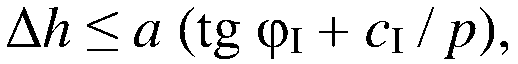

In [7]:
from doclayout_yolo import YOLOv10
from huggingface_hub import hf_hub_download
from IPython.display import Image, display

weights = hf_hub_download(
    "juliozhao/DocLayout-YOLO-DocStructBench",
    "doclayout_yolo_docstructbench_imgsz1024.pt",
)
model = YOLOv10(weights)

img = cv2.imread(str(ROOT / "normatives_pipeline" / "research" / "pages" / "page_038.png"))
res = model.predict(img, conf=0.25, imgsz=1024)

out_dir = ROOT / "normatives_pipeline" / "research" / "crops"
out_dir.mkdir(parents=True, exist_ok=True)

formula_crops = []
for r in res:
    for box, cls, conf in zip(r.boxes.xyxy, r.boxes.cls, r.boxes.conf):
        if r.names[int(cls)] == "isolate_formula":
            x1, y1, x2, y2 = [int(v) for v in box]
            crop = img[y1:y2, x1:x2]
            path = out_dir / f"page_038_formula_{len(formula_crops)}.png"
            cv2.imwrite(str(path), crop)
            formula_crops.append((path, (x1, y1, x2, y2), float(conf)))

print(f"найдено формул: {len(formula_crops)}")
for path, box, conf in formula_crops:
    print(path.name, box, f"conf={conf:.2f}")
    display(Image(filename=str(path)))


In [8]:
from pix2text import LatexOCR

recognizer = LatexOCR(device="cpu")

for path, box, conf in formula_crops:
    result = recognizer.recognize(str(path))
    print(f"{path.name}:  score={result['score']:.4f}")
    print(result["text"])
    print()


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Could not find any ONNX files with standard file name decoder_model_merged.onnx, files found: [PosixPath('encoder_model.onnx'), PosixPath('decoder_model.onnx')]. Please make sure to pass a `file_name` and/or `subfolder` argument to `from_pretrained` when loading an ONNX file with non-standard file names.
100%|██████████| 1/1 [00:01<00:00,  1.17s/it]

page_038_formula_0.png:  score=0.9786
\Delta h \leq a ~ ( \mathrm{t g} ~ \varphi_{\mathrm{I}}+\, c_{\mathrm{I}} \, / \, p ) ,



$$\Delta h \leq a ~ ( \mathrm{t g} ~ \varphi_{\mathrm{I}}+\, c_{\mathrm{I}} \, / \, p ) ,$$

In [9]:
from normatives_pipeline.ocr.correct import correct_latex

for path, box, conf in formula_crops:
    raw = recognizer.recognize(str(path))["text"]
    corrected = correct_latex(raw)
    print(f"{path.name}:")
    print(f"  raw:       {raw}")
    print(f"  corrected: {corrected}")
    print()


100%|██████████| 1/1 [00:01<00:00,  1.05s/it]

page_038_formula_0.png:
  raw:       \Delta h \leq a ~ ( \mathrm{t g} ~ \varphi_{\mathrm{I}}+\, c_{\mathrm{I}} \, / \, p ) ,
  corrected: \Delta h \leq a ( \mathrm{tg} \varphi_{\mathrm{I}}+ c_{\mathrm{I}} / p )



$$\Delta h \leq a ( \mathrm{tg} \varphi_{\mathrm{I}}+ c_{\mathrm{I}} / p )$$

In [10]:
import re
import tomllib
from difflib import SequenceMatcher

from PIL import Image as PILImage
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

from doclayout_yolo import YOLOv10
from huggingface_hub import hf_hub_download
from pix2text import LatexOCR
from normatives_pipeline.ocr.correct import correct_latex


class DetectFormulaRegions(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return [self._detect(img) for img in X]

    def _detect(self, img):
        crops = []
        for r in detector.predict(img, conf=0.25, imgsz=1024):
            for box, cls in zip(r.boxes.xyxy, r.boxes.cls):
                if r.names[int(cls)] == "isolate_formula":
                    x1, y1, x2, y2 = [int(v) for v in box]
                    crops.append(img[y1:y2, x1:x2])
        return crops


class RecognizeToLatex(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return [
            [recognizer.recognize(PILImage.fromarray(crop[..., ::-1]))["text"] for crop in crops]
            for crops in X
        ]


class CorrectLatexStep(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return [[correct_latex(s) for s in formulas] for formulas in X]


weights = hf_hub_download(
    "juliozhao/DocLayout-YOLO-DocStructBench",
    "doclayout_yolo_docstructbench_imgsz1024.pt",
)
detector = YOLOv10(weights)
recognizer = LatexOCR(device="cpu")

pipeline = Pipeline([
    ("detect", DetectFormulaRegions()),
    ("recognize", RecognizeToLatex()),
    ("correct", CorrectLatexStep()),
])


def normalize(latex: str) -> str:
    s = re.sub(r"\\mathrm\{([^}]*)\}", r"\1", latex)
    s = re.sub(r"\\operatorname\{([^}]*)\}", r"\1", s)
    s = re.sub(r"\\left|\\right|\\,|\\!|\\;|~", "", s)
    s = re.sub(r"\s+", "", s)
    return s


def similarity(a: str, b: str) -> float:
    return SequenceMatcher(None, normalize(a), normalize(b)).ratio()


validation = tomllib.loads(
    (ROOT / "normatives_pipeline" / "research" / "validation.toml").read_text(encoding="utf-8")
)["formula"]

results = []
for entry in validation:
    page_no = entry["page"]
    page_path = ROOT / "normatives_pipeline" / "research" / "pages" / f"page_{page_no:03d}.png"
    img = cv2.imread(str(page_path))
    preds = pipeline.fit_transform([img])[0]
    etalon = entry["latex"]
    best = max((similarity(p, etalon) for p in preds), default=0.0)
    results.append((entry["number"], page_no, len(preds), best))

for number, page_no, n_det, best in results:
    print(f"формула {number} (стр. {page_no}): детекций {n_det}, best_sim={best:.3f}")

print(f"\nmean similarity = {sum(r[3] for r in results) / len(results):.3f}")


Could not find any ONNX files with standard file name decoder_model_merged.onnx, files found: [PosixPath('encoder_model.onnx'), PosixPath('decoder_model.onnx')]. Please make sure to pass a `file_name` and/or `subfolder` argument to `from_pretrained` when loading an ONNX file with non-standard file names.



0: 1024x736 15 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 90.1ms
Speed: 9.9ms preprocess, 90.1ms inference, 3.9ms postprocess per image at shape (1, 3, 1024, 736)


100%|██████████| 1/1 [00:00<00:00,  1.50it/s]

0: 1024x736 1 title, 13 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 98.0ms
Speed: 7.5ms preprocess, 98.0ms inference, 6.1ms postprocess per image at shape (1, 3, 1024, 736)


100%|██████████| 1/1 [00:01<00:00,  1.41s/it]

0: 1024x736 1 title, 16 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 159.7ms
Speed: 9.7ms preprocess, 159.7ms inference, 10.0ms postprocess per image at shape (1, 3, 1024, 736)


100%|██████████| 1/1 [00:07<00:00,  7.24s/it]

формула 5.1 (стр. 29): детекций 1, best_sim=0.682
формула 5.5 (стр. 38): детекций 1, best_sim=0.939
формула 5.7 (стр. 40): детекций 1, best_sim=0.671

mean similarity = 0.764


In [ ]:
import urllib.request
import zipfile

DATA_DIR = ROOT / "normatives_pipeline" / "research" / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

BASE = "https://zenodo.org/api/records/7738969/files"

dataset_dir = DATA_DIR / "im2latex-230k"
images_dir = dataset_dir / "generated_png_images"
formulas_file = dataset_dir / "final_png_formulas.txt"

if not (images_dir.exists() and formulas_file.exists()):
    dataset_dir.mkdir(parents=True, exist_ok=True)

    zip_path = DATA_DIR / "PRINTED_TEX_230k.zip"
    if not zip_path.exists():
        print("скачиваем PRINTED_TEX_230k.zip (~1 ГБ)…")
        urllib.request.urlretrieve(f"{BASE}/PRINTED_TEX_230k.zip/content", zip_path)

    print("распаковываем…")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dataset_dir)
    zip_path.unlink()

    print("готово:", dataset_dir)
else:
    print("датасет уже есть:", dataset_dir)
